# Data Understanding & Exploratory Data Analysis

## Student Interest Profile Segmentation Using Clustering

Notebook ini bertujuan untuk memahami struktur, karakteristik, dan kualitas dataset sebelum dilakukan preprocessing dan clustering.

Tahapan yang dilakukan:
1. Dataset overview and structure.
2. Feature identification.
3. Data quality analysis.
4. Profile feature analysis.
5. Interest feature analysis.
6. Correlation analysis.
7. EDA findings and preprocessing recommendations.

Catatan: Notebook ini hanya berfokus pada Data Understanding dan EDA. 
Tidak ada proses data cleaning, scaling, normalization, maupun model development.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

# Mengatur tampilan DataFrame
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")

# Lokasi proyek: folder induk notebooks jika ada folder data di sana (struktur lokal),
# selain itu folder kerja saat ini (Colab atau Kaggle)
PROJECT_ROOT = Path("..") if Path("../data").exists() else Path(".")
DATASET_NAMES = ("Clustering_Marketing.csv", "03_Clustering_Marketing.csv")


def find_dataset():
    # Cek lokasi yang umum dipakai di lokal dan Colab
    for folder in (PROJECT_ROOT / "data", Path("data"), Path("."), Path("/content"), Path("/content/data")):
        for name in DATASET_NAMES:
            if (folder / name).exists():
                return folder / name
    # Di Kaggle, dataset ada di dalam /kaggle/input/<nama-dataset>/
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for name in DATASET_NAMES:
            found = next(kaggle_input.rglob(name), None)
            if found is not None:
                return found
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Taruh Clustering_Marketing.csv di folder data/, "
        "upload ke folder kerja Colab, atau tambahkan sebagai Input di Kaggle."
    )


DATA_PATH = find_dataset()

# Folder untuk menyimpan hasil analisis EDA
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "EDA"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("Libraries imported successfully.")
print(f"Dataset path: {DATA_PATH.resolve()}")

Libraries imported successfully.
Dataset path: C:\Users\WIN 11\Desktop\CS\Machine Learning Mikroskil\UTS\data\Clustering_Marketing.csv


## 2. Load Dataset

Memuat dataset yang digunakan dalam penelitian.

Dataset yang digunakan berasal dari Kaggle:
Students Social Network Profile Clustering.

In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

Dataset loaded successfully.
Dataset shape: 15,000 rows x 40 columns


In [3]:
# Menampilkan lima baris pertama
display(df.head())

,gradyear,gender,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,tennis,sports,cute,sex,sexy,hot,kissed,dance,band,marching,music,rock,god,church,jesus,bible,hair,dress,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2007,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2007,F,17.41,49,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,2007,F,17.511,41,0,0,0,0,0,0,0,1,0,0,0,3,0,0,0,0,0,0,1,2,0,1,0,0,4,0,0,1,0,0,0,0,0,0,1,1
3,2006,F,NaN,36,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2008,F,16.657,1,0,0,0,0,0,1,0,0,3,0,6,0,2,0,0,0,0,0,1,0,1,1,0,0,5,0,0,0,0,3,0,0,0,0,0,0


## 3. Dataset Structure

Tahap ini digunakan untuk memahami struktur dataset, termasuk:
- Jumlah observasi dan fitur.
- Nama kolom.
- Tipe data setiap kolom.
- Jumlah nilai unik.
- Statistik deskriptif.

In [4]:
# Informasi umum dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 15000
Number of columns: 40


In [5]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['gradyear', 'gender', 'age', 'NumberOffriends', 'basketball', 'football', 'soccer', 'softball', 'volleyball', 'swimming', 'cheerleading', 'baseball', 'tennis', 'sports', 'cute', 'sex', 'sexy', 'hot', 'kissed', 'dance', 'band', 'marching', 'music', 'rock', 'god', 'church', 'jesus', 'bible', 'hair', 'dress', 'blonde', 'mall', 'shopping', 'clothes', 'hollister', 'abercrombie', 'die', 'death', 'drunk', 'drugs']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 40 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   gradyear         15000 non-null  int64
 1   gender           13663 non-null  str  
 2   age              12504 non-null  str  
 3   NumberOffriends  15000 non-null  int64
 4   basketball       15000 non-null  int64
 5   football         15000 non-null  int64
 6   soccer           15000 non-null  int64
 7   softball         15000 non-null  int64
 8   volleyball       15000 non-null  int64
 9   swimming         15000 non-null  int64
 10  cheerleading     15000 non-null  int64
 11  baseball         15000 non-null  int64
 12  tennis           15000 non-null  int64
 13  sports           15000 non-null  int64
 14  cute             15000 non-null  int64
 15  sex              15000 non-null  int64
 16  sexy             15000 non-null  int64
 17  hot              15000 non-null  int64
 18  kissed           

In [7]:
# Ringkasan karakteristik setiap kolom
column_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Unique Values": df.nunique(dropna=False),
    "Missing Values": df.isna().sum()
})

display(column_summary)

column_summary.to_csv(
    TABLE_DIR / "dataset_column_summary.csv"
)

,Data Type,Unique Values,Missing Values
gradyear,int64,4,0
gender,str,3,1337
age,str,1907,2496
NumberOffriends,int64,236,0
basketball,int64,13,0
football,int64,10,0
soccer,int64,17,0
softball,int64,16,0
volleyball,int64,13,0
swimming,int64,11,0


In [8]:
# Statistik deskriptif seluruh kolom
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gradyear,15000.000,NaN,NaN,NaN,2007.497,1.117,2006.000,2006.000,2008.000,2008.000,2009.000
gender,13663,2,F,11057,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,12504,1906,16. Jun,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NumberOffriends,15000.000,NaN,NaN,NaN,29.835,35.387,0.000,3.000,20.000,44.000,605.000
basketball,15000.000,NaN,NaN,NaN,0.267,0.789,0.000,0.000,0.000,0.000,22.000
football,15000.000,NaN,NaN,NaN,0.255,0.702,0.000,0.000,0.000,0.000,9.000
soccer,15000.000,NaN,NaN,NaN,0.222,0.920,0.000,0.000,0.000,0.000,22.000
softball,15000.000,NaN,NaN,NaN,0.160,0.737,0.000,0.000,0.000,0.000,17.000
volleyball,15000.000,NaN,NaN,NaN,0.143,0.639,0.000,0.000,0.000,0.000,14.000
swimming,15000.000,NaN,NaN,NaN,0.135,0.549,0.000,0.000,0.000,0.000,31.000


## 4. Feature Identification

Berdasarkan struktur dataset, fitur dibagi menjadi dua kelompok:

1. Profile Features:
   - gradyear
   - gender
   - age
   - NumberOffriends

2. Interest Features:
   - 36 fitur yang merepresentasikan informasi minat pada profil.

Pemisahan ini digunakan untuk mempermudah analisis dataset.
Keputusan final mengenai fitur yang digunakan untuk clustering
akan ditentukan pada tahap preprocessing.

In [9]:
# Kolom informasi profil
profile_cols = [
    "gradyear",
    "gender",
    "age",
    "NumberOffriends"
]

# Memastikan semua kolom profil tersedia
missing_profile_cols = [
    col for col in profile_cols
    if col not in df.columns
]

if missing_profile_cols:
    raise ValueError(
        f"Profile columns not found: {missing_profile_cols}"
    )

# Mengidentifikasi kolom yang bukan fitur minat
unnamed_cols = [
    col for col in df.columns
    if str(col).startswith("Unnamed:")
]

# Mengidentifikasi fitur minat
interest_cols = [
    col for col in df.columns
    if col not in profile_cols
    and col not in unnamed_cols
]

print("Profile Features:", len(profile_cols))
print(profile_cols)

print("\nInterest Features:", len(interest_cols))
print(interest_cols)

print("\nUnnamed Columns:", unnamed_cols)

if len(interest_cols) != 36:
    print(
        "Warning: Number of interest features "
        "is different from the expected 36."
    )

Profile Features: 4
['gradyear', 'gender', 'age', 'NumberOffriends']

Interest Features: 36
['basketball', 'football', 'soccer', 'softball', 'volleyball', 'swimming', 'cheerleading', 'baseball', 'tennis', 'sports', 'cute', 'sex', 'sexy', 'hot', 'kissed', 'dance', 'band', 'marching', 'music', 'rock', 'god', 'church', 'jesus', 'bible', 'hair', 'dress', 'blonde', 'mall', 'shopping', 'clothes', 'hollister', 'abercrombie', 'die', 'death', 'drunk', 'drugs']

Unnamed Columns: []


## 5. Data Quality Analysis

### 5.1 Missing Value Analysis

Mengidentifikasi jumlah dan persentase missing values
pada setiap kolom.

Analisis ini bertujuan mengetahui kualitas data sebelum
menentukan strategi penanganan missing values pada
tahap preprocessing.

In [10]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

# Hanya mengambil kolom yang memiliki missing values
missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Count",
    ascending=False
)

if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary.round(2))

    missing_summary.to_csv(
        TABLE_DIR / "missing_value_summary.csv"
    )

,Missing Count,Missing Percentage
age,2496,16.640
gender,1337,8.910


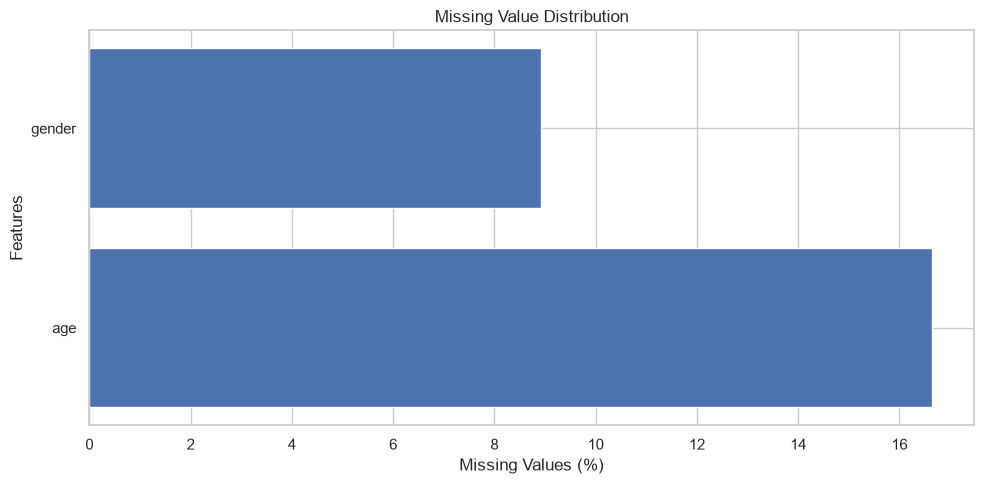

In [11]:
# Visualisasi missing values
if not missing_summary.empty:

    plt.figure(figsize=(10, 5))

    plt.barh(
        missing_summary.index,
        missing_summary["Missing Percentage"]
    )

    plt.xlabel("Missing Values (%)")
    plt.ylabel("Features")
    plt.title("Missing Value Distribution")

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / "missing_value_distribution.png",
        dpi=150
    )

    plt.show()

### 5.2 Duplicate Data Analysis

Memeriksa apakah terdapat baris yang memiliki nilai
identik pada seluruh kolom dataset.

Tujuan analisis ini adalah mengidentifikasi kemungkinan
duplikasi observasi.

Baris duplikat tidak langsung dihapus karena perlu
dipastikan terlebih dahulu apakah duplikasi tersebut
merupakan kesalahan data.

In [12]:
# Menghitung full duplicate rows
duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df) * 100
)

print("Total duplicate rows:", duplicate_count)

print(
    f"Duplicate percentage: {duplicate_percentage:.2f}%"
)

# Melihat contoh baris duplikat
duplicate_rows = df[
    df.duplicated(keep=False)
]

display(
    duplicate_rows.head(10)
)

Total duplicate rows: 266
Duplicate percentage: 1.77%


,gradyear,gender,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,tennis,sports,cute,sex,sexy,hot,kissed,dance,band,marching,music,rock,god,church,jesus,bible,hair,dress,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2007,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,2006,F,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
11,2006,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
27,2007,NaN,NaN,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
137,2009,NaN,NaN,25,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
146,2006,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
223,2009,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
226,2008,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
259,2006,F,NaN,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
272,2007,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 6. Profile Feature Analysis

### 6.1 Graduation Year Distribution

Menganalisis distribusi tahun kelulusan untuk mengetahui
jumlah profil pada setiap tahun.

In [13]:
gradyear_summary = (
    df["gradyear"]
    .fillna("Missing")
    .astype(str)
    .value_counts()
    .sort_index()
)

gradyear_table = pd.DataFrame({
    "Profile Count": gradyear_summary,
    "Percentage": (
        gradyear_summary / len(df) * 100
    )
})

display(gradyear_table)

gradyear_table.to_csv(
    TABLE_DIR / "graduation_year_summary.csv"
)

,Profile Count,Percentage
gradyear,,
2006,3761,25.073
2007,3737,24.913
2008,3789,25.260
2009,3713,24.753


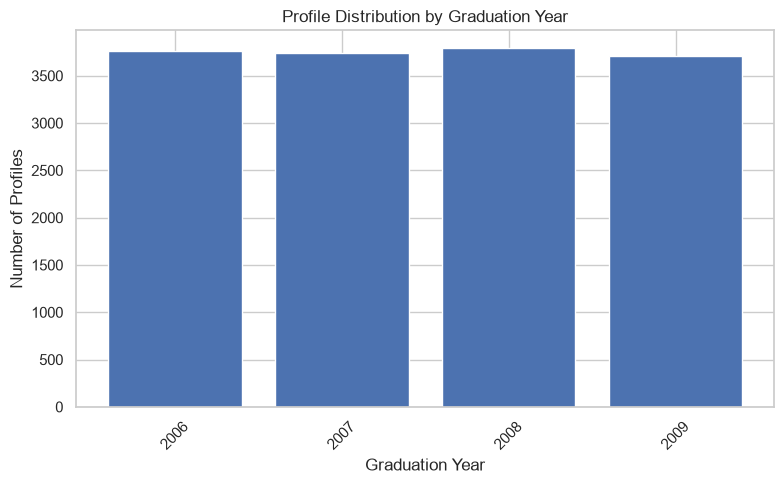

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    gradyear_summary.index,
    gradyear_summary.values
)

plt.xlabel("Graduation Year")
plt.ylabel("Number of Profiles")

plt.title("Profile Distribution by Graduation Year")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "graduation_year_distribution.png",
    dpi=150
)

plt.show()

### 6.2 Gender Distribution

Menganalisis distribusi kategori gender untuk mengetahui
proporsi setiap kategori serta jumlah profil yang tidak
memiliki informasi gender.

In [15]:
gender_summary = (
    df["gender"]
    .fillna("Missing")
    .astype(str)
    .value_counts()
)

gender_table = pd.DataFrame({
    "Profile Count": gender_summary,
    "Percentage": (
        gender_summary / len(df) * 100
    )
})

display(gender_table)

gender_table.to_csv(
    TABLE_DIR / "gender_summary.csv"
)

,Profile Count,Percentage
gender,,
F,11057,73.713
M,2606,17.373
Missing,1337,8.913


### 6.3 Age Distribution and Validation

Menganalisis distribusi umur serta memeriksa nilai yang
tidak dapat dikonversi menjadi numerik.

Pemeriksaan ini diperlukan karena kolom age berpotensi
mengandung missing values, format teks yang tidak konsisten,
atau nilai numerik yang tidak wajar.

In [16]:
# Mengubah kolom age menjadi numerik
# errors="coerce" mengubah nilai yang tidak valid menjadi NaN

age_numeric = pd.to_numeric(
    df["age"],
    errors="coerce"
)

# Memeriksa missing dan invalid values
original_missing_age = df["age"].isnull().sum()

invalid_age = (
    df["age"].notna()
    & age_numeric.isna()
).sum()

print("Original missing age:", original_missing_age)
print("Invalid age format:", invalid_age)

print("\nAge descriptive statistics:")
display(age_numeric.describe())

Original missing age: 2496
Invalid age format: 276

Age descriptive statistics:


count   12228.000
mean       17.988
std         7.716
min         4.309
25%        16.331
50%        17.295
75%        18.264
max       106.927
Name: age, dtype: float64

In [17]:
# Memeriksa nilai umur yang perlu diinvestigasi
age_outside_range = (
    age_numeric.notna()
    & ~age_numeric.between(13, 25)
)

age_negative = age_numeric < 0
age_above_100 = age_numeric > 100

print(
    "Numeric ages outside 13-25:",
    age_outside_range.sum()
)

print(
    "Negative ages:",
    age_negative.sum()
)

print(
    "Ages above 100:",
    age_above_100.sum()
)

age_check = pd.DataFrame({
    "Original Age": df["age"],
    "Numeric Age": age_numeric
})

display(
    age_check.loc[
        age_outside_range
        | age_negative
        | age_above_100
    ].head(20)
)

Numeric ages outside 13-25: 153
Negative ages: 0
Ages above 100: 77


,Original Age,Numeric Age
112,8.808,8.808
117,106.746,106.746
253,106.13,106.130
264,105.971,105.971
450,45.281,45.281
570,105.988,105.988
616,103.959,103.959
995,106.313,106.313
1003,61.035,61.035
1085,106.913,106.913


In [18]:
# Melihat contoh nilai age yang tidak valid
invalid_age_values = df.loc[
    df["age"].notna() & age_numeric.isna(),
    "age"
]

print("Jumlah baris age tidak valid:", len(invalid_age_values))
print("Jumlah nilai unik:", invalid_age_values.nunique())

display(
    invalid_age_values.value_counts().head(15)
)

Jumlah baris age tidak valid: 276
Jumlah nilai unik: 33


age
16. Jun    24
17. Jul    19
16. Nov    16
16. Feb    15
18. Jul    14
17. Mrz    14
18. Jan    14
17. Apr    13
17. Jan    12
17. Mai    12
17. Sep    11
17. Jun    10
18. Apr     9
16. Dez     9
18. Mai     8
Name: count, dtype: int64

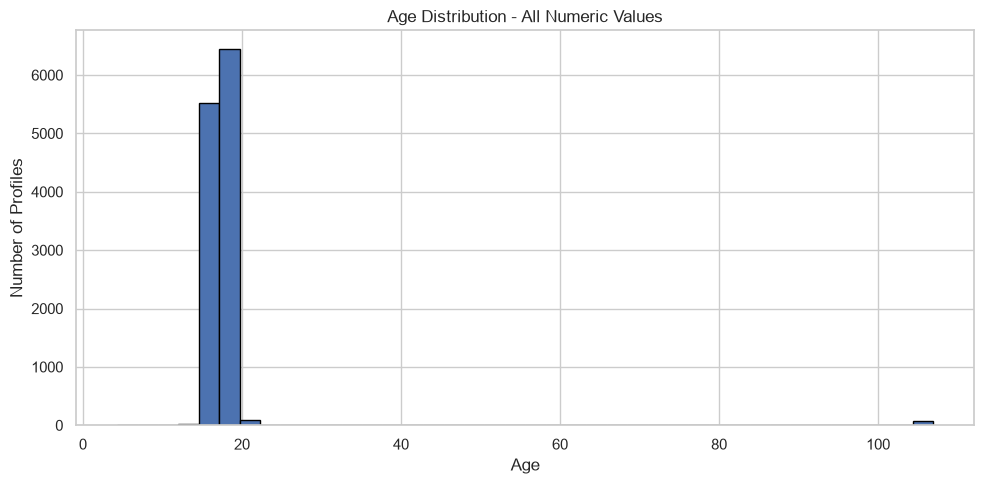

In [19]:
# Visualisasi seluruh umur numerik
age_valid = age_numeric.dropna()

plt.figure(figsize=(10, 5))

plt.hist(
    age_valid,
    bins=40,
    edgecolor="black"
)

plt.xlabel("Age")
plt.ylabel("Number of Profiles")

plt.title("Age Distribution - All Numeric Values")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "age_distribution_all.png",
    dpi=150
)

plt.show()

### 6.4 Number of Friends Distribution

Menganalisis distribusi jumlah teman pada setiap profil.

Pemeriksaan ini mencakup statistik deskriptif, nilai
yang tidak dapat dikonversi, dan kemungkinan nilai ekstrem.

In [21]:
friends_numeric = pd.to_numeric(
    df["NumberOffriends"],
    errors="coerce"
)

friends_invalid = (
    df["NumberOffriends"].notna()
    & friends_numeric.isna()
).sum()

print(
    "Original missing values:",
    df["NumberOffriends"].isnull().sum()
)

print(
    "Invalid numeric values:",
    friends_invalid
)

print(
    "Negative values:",
    (friends_numeric < 0).sum()
)

print("\nNumber of Friends Statistics:")

display(
    friends_numeric.describe()
)

Original missing values: 0
Invalid numeric values: 0
Negative values: 0

Number of Friends Statistics:


count   15000.000
mean       29.835
std        35.387
min         0.000
25%         3.000
50%        20.000
75%        44.000
max       605.000
Name: NumberOffriends, dtype: float64

## 7. Interest Feature Analysis

Bagian ini berfokus pada karakteristik 36 fitur minat.

Fitur-fitur tersebut akan diperiksa untuk mengetahui:
- Statistik deskriptif.
- Validitas nilai.
- Distribusi nilai nol.
- Sparsity.
- Frekuensi kemunculan topik.
- Distribusi dan nilai ekstrem.

In [22]:
# Membuat salinan fitur minat untuk kebutuhan EDA
X_interest = df[interest_cols].copy()

# Memastikan seluruh fitur dapat diperiksa sebagai numerik
X_interest = X_interest.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Interest feature shape:", X_interest.shape)

print(
    "Missing values after numeric conversion:",
    X_interest.isna().sum().sum()
)

Interest feature shape: (15000, 36)
Missing values after numeric conversion: 0


### 7.1 Descriptive Statistics

In [23]:
interest_statistics = X_interest.describe().T

display(interest_statistics)

interest_statistics.to_csv(
    TABLE_DIR / "interest_descriptive_statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max
basketball,15000.000,0.267,0.789,0.000,0.000,0.000,0.000,22.000
football,15000.000,0.255,0.702,0.000,0.000,0.000,0.000,9.000
soccer,15000.000,0.222,0.920,0.000,0.000,0.000,0.000,22.000
softball,15000.000,0.160,0.737,0.000,0.000,0.000,0.000,17.000
volleyball,15000.000,0.143,0.639,0.000,0.000,0.000,0.000,14.000
swimming,15000.000,0.135,0.549,0.000,0.000,0.000,0.000,31.000
cheerleading,15000.000,0.105,0.502,0.000,0.000,0.000,0.000,8.000
baseball,15000.000,0.104,0.519,0.000,0.000,0.000,0.000,14.000
tennis,15000.000,0.088,0.530,0.000,0.000,0.000,0.000,15.000
sports,15000.000,0.144,0.476,0.000,0.000,0.000,0.000,12.000


### 7.2 Percentile and IQR Analysis

In [24]:
# Memeriksa distribusi percentile setiap fitur minat
percentile_summary = pd.DataFrame({
    "P95": X_interest.quantile(0.95),
    "P99": X_interest.quantile(0.99),
    "P99.5": X_interest.quantile(0.995),
    "Maximum": X_interest.max()
})

percentile_summary = percentile_summary.sort_values(
    by="P99",
    ascending=False
)

display(percentile_summary.round(2))

# Menghitung berapa fitur yang memiliki P99 <= 2
features_p99_below_2 = (
    percentile_summary["P99"] <= 2
).sum()

print(
    f"Features with P99 <= 2: "
    f"{features_p99_below_2}/{len(interest_cols)}"
)

print(
    "\nFeatures with P99 > 2:"
)

display(
    percentile_summary[
        percentile_summary["P99"] > 2
    ]
)

,P95,P99,P99.5,Maximum
soccer,1.000,5.000,6.000,22
dance,2.000,5.000,7.000,29
music,3.000,5.000,6.000,23
band,2.000,5.000,7.000,27
hair,2.000,5.000,6.000,21
god,2.000,5.000,7.000,52
basketball,2.000,4.000,5.000,22
softball,1.000,4.000,5.000,17
sex,1.000,4.000,5.000,114
church,2.000,4.000,5.000,17


Features with P99 <= 2: 17/36

Features with P99 > 2:


,P95,P99,P99.5,Maximum
soccer,1.000,5.000,6.000,22
dance,2.000,5.000,7.000,29
music,3.000,5.000,6.000,23
band,2.000,5.000,7.000,27
hair,2.000,5.000,6.000,21
god,2.000,5.000,7.000,52
basketball,2.000,4.000,5.000,22
softball,1.000,4.000,5.000,17
sex,1.000,4.000,5.000,114
church,2.000,4.000,5.000,17


In [25]:
# Menghitung Q1, Q3, dan IQR setiap fitur
q1 = X_interest.quantile(0.25)
q3 = X_interest.quantile(0.75)

iqr = q3 - q1

# Membuat ringkasan IQR
iqr_summary = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr
})

display(iqr_summary)

# Menghitung jumlah fitur berdasarkan nilai IQR
zero_iqr_count = (iqr == 0).sum()
nonzero_iqr_count = (iqr > 0).sum()

print("Features with IQR = 0:", zero_iqr_count)
print("Features with IQR > 0:", nonzero_iqr_count)

print("\nFeatures with non-zero IQR:")
display(iqr[iqr > 0])

,Q1,Q3,IQR
basketball,0.000,0.000,0.000
football,0.000,0.000,0.000
soccer,0.000,0.000,0.000
softball,0.000,0.000,0.000
volleyball,0.000,0.000,0.000
swimming,0.000,0.000,0.000
cheerleading,0.000,0.000,0.000
baseball,0.000,0.000,0.000
tennis,0.000,0.000,0.000
sports,0.000,0.000,0.000


Features with IQR = 0: 33
Features with IQR > 0: 3

Features with non-zero IQR:


music      1.000
god        1.000
shopping   1.000
dtype: float64

### 7.3 Feature Data Validation

Memeriksa apakah fitur minat memiliki nilai:
- Missing values.
- Negative values.
- Non-integer values.

Pemeriksaan ini berguna untuk memahami kualitas data
sebelum menentukan metode preprocessing.

In [26]:
missing_features = X_interest.isnull().sum()

negative_features = (
    X_interest < 0
).sum()

non_integer_features = (
    X_interest.notna()
    & (X_interest % 1 != 0)
).sum()

validation_summary = pd.DataFrame({
    "Missing Values": missing_features,
    "Negative Values": negative_features,
    "Non-Integer Values": non_integer_features,
    "Data Type": X_interest.dtypes.astype(str)
})

display(validation_summary)

print("\nTotal missing:", X_interest.isna().sum().sum())

print(
    "Total negative:",
    (X_interest < 0).sum().sum()
)

print(
    "Total non-integer:",
    (
        X_interest.notna()
        & (X_interest % 1 != 0)
    ).sum().sum()
)

validation_summary.to_csv(
    TABLE_DIR / "interest_feature_validation.csv"
)

,Missing Values,Negative Values,Non-Integer Values,Data Type
basketball,0,0,0,int64
football,0,0,0,int64
soccer,0,0,0,int64
softball,0,0,0,int64
volleyball,0,0,0,int64
swimming,0,0,0,int64
cheerleading,0,0,0,int64
baseball,0,0,0,int64
tennis,0,0,0,int64
sports,0,0,0,int64



Total missing: 0
Total negative: 0
Total non-integer: 0


### 7.4 Sparsity Analysis

Sparsity menunjukkan seberapa besar proporsi nilai nol
dalam matriks fitur minat.

Analisis ini penting karena banyaknya nilai nol dapat
memengaruhi perhitungan jarak antarprofil pada algoritma
clustering.

In [27]:
total_cells = X_interest.size

valid_cells = X_interest.notna().sum().sum()

zero_count = X_interest.eq(0).sum().sum()

missing_count = X_interest.isna().sum().sum()

sparsity = (
    zero_count / valid_cells * 100
    if valid_cells > 0 else np.nan
)

print("Total cells:", total_cells)

print("Valid cells:", valid_cells)

print("Zero values:", zero_count)

print("Missing values:", missing_count)

print(f"Sparsity: {sparsity:.2f}%")

Total cells: 540000
Valid cells: 540000
Zero values: 474142
Missing values: 0
Sparsity: 87.80%


### 7.5 Number of Recorded Interests per Profile

Menghitung jumlah fitur minat yang memiliki nilai lebih
dari nol pada setiap profil.

Analisis ini digunakan untuk mengetahui apakah sebagian
besar profil hanya memiliki sedikit informasi minat.

In [28]:
topics_per_profile = (
    X_interest.gt(0).sum(axis=1)
)

print("Topics per profile statistics:")

display(
    topics_per_profile.describe()
)

print(
    "\nProfiles with no recorded interest:",
    (topics_per_profile == 0).sum()
)

Topics per profile statistics:


count   15000.000
mean        4.391
std         3.409
min         0.000
25%         2.000
50%         4.000
75%         6.000
max        31.000
dtype: float64


Profiles with no recorded interest: 1238


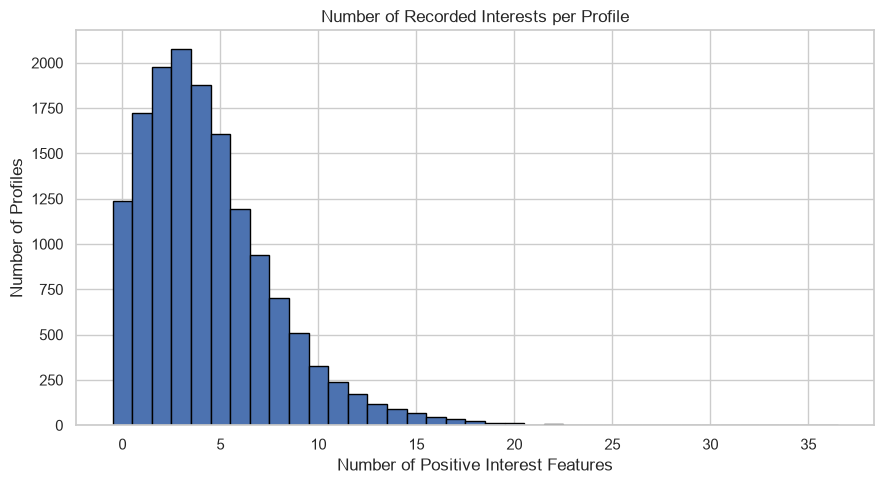

In [29]:
plt.figure(figsize=(9, 5))

plt.hist(
    topics_per_profile,
    bins=np.arange(
        -0.5,
        len(interest_cols) + 1.5,
        1
    ),
    edgecolor="black"
)

plt.xlabel("Number of Positive Interest Features")
plt.ylabel("Number of Profiles")

plt.title("Number of Recorded Interests per Profile")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "topics_per_profile_distribution.png",
    dpi=150
)

plt.show()

### 7.6 All-Zero Interest Profiles

Mengidentifikasi profil yang seluruh 36 fitur minatnya
memiliki nilai nol.

Profil seperti ini perlu diperhatikan karena tidak memiliki
informasi positif pada fitur minat yang digunakan dalam
penelitian.

Pada tahap EDA, profil ini hanya diidentifikasi dan
dilaporkan. Keputusan untuk mempertahankan atau
mengecualikannya akan dilakukan pada tahap preprocessing.

In [30]:
all_zero_profiles = X_interest.eq(0).all(axis=1)

total_zero_profiles = all_zero_profiles.sum()

zero_profile_percentage = (
    total_zero_profiles / len(X_interest) * 100
)

print(
    "Profiles with all-zero interests:",
    total_zero_profiles
)

print(
    f"Percentage: {zero_profile_percentage:.2f}%"
)

# Melihat contoh profil all-zero
display(
    df.loc[all_zero_profiles, profile_cols].head(10)
)

Profiles with all-zero interests: 1238
Percentage: 8.25%


,gradyear,gender,age,NumberOffriends
0,2007,NaN,NaN,0
3,2006,F,NaN,36
7,2006,F,NaN,0
11,2006,NaN,NaN,0
17,2009,F,15.696,98
24,2007,M,18.136,18
27,2007,NaN,NaN,12
28,2009,M,17.095,85
55,2007,F,17.202,41
64,2006,M,18.825,12


### 7.7 Topic Distribution

Mengidentifikasi fitur minat yang paling sering muncul
di antara seluruh profil.

Profile Count dihitung berdasarkan jumlah profil dengan
nilai fitur lebih dari nol.

Total Values menunjukkan jumlah seluruh nilai dari
fitur tersebut.

In [31]:
topic_summary = pd.DataFrame({
    "Profile Count": X_interest.gt(0).sum(),
    "Profile Percentage": X_interest.gt(0).mean() * 100,
    "Total Values": X_interest.sum(),
    "Mean Value": X_interest.mean(),
    "Median Value": X_interest.median(),
    "Maximum Value": X_interest.max()
})

topic_summary = topic_summary.sort_values(
    by="Profile Count",
    ascending=False
)

display(topic_summary)

topic_summary.to_csv(
    TABLE_DIR / "topic_summary.csv"
)

,Profile Count,Profile Percentage,Total Values,Mean Value,Median Value,Maximum Value
music,6661,44.407,10994,0.733,0.000,23
god,3980,26.533,7124,0.475,0.000,52
shopping,3856,25.707,5359,0.357,0.000,11
hair,3407,22.713,6468,0.431,0.000,21
dance,3323,22.153,6463,0.431,0.000,29
cute,3114,20.760,4921,0.328,0.000,14
mall,2633,17.553,3892,0.259,0.000,12
football,2499,16.660,3832,0.255,0.000,9
rock,2452,16.347,3688,0.246,0.000,18
basketball,2412,16.080,4005,0.267,0.000,22


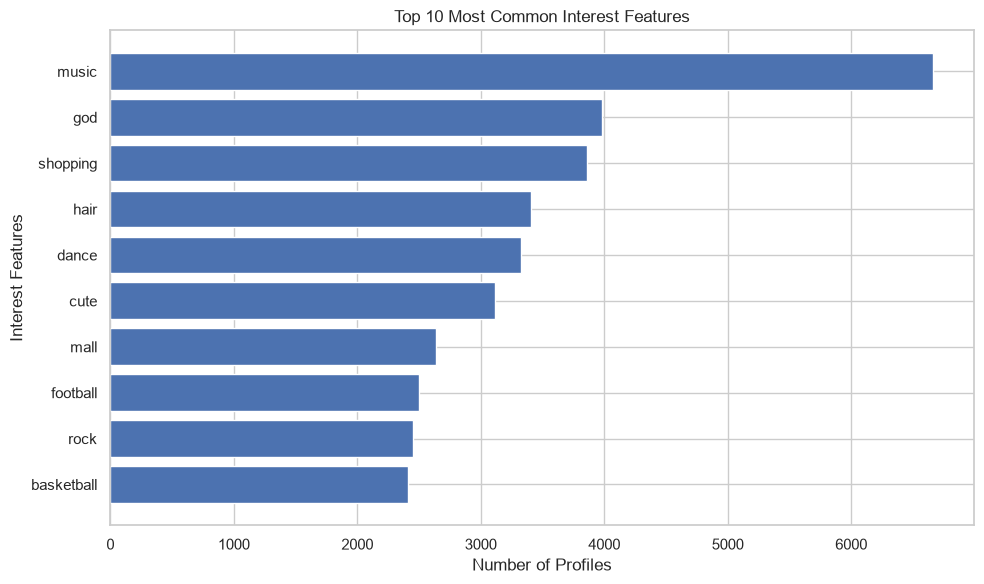

In [32]:
top_10_topics = (
    topic_summary.head(10)
    .sort_values("Profile Count")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_topics.index,
    top_10_topics["Profile Count"]
)

plt.xlabel("Number of Profiles")
plt.ylabel("Interest Features")

plt.title("Top 10 Most Common Interest Features")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "top_10_interest_features.png",
    dpi=150
)

plt.show()

### 7.8 Feature Distribution and Extreme Values

Menganalisis distribusi setiap fitur minat menggunakan:
- Mean.
- Median.
- Maximum.
- Skewness.
- Jumlah profil dengan nilai positif.

Pemeriksaan ini membantu mengetahui fitur yang memiliki
distribusi tidak simetris atau nilai ekstrem.

Nilai yang teridentifikasi sebagai ekstrem tidak otomatis
dianggap sebagai kesalahan data.

In [33]:
feature_distribution = pd.DataFrame({
    "Mean": X_interest.mean(),
    "Median": X_interest.median(),
    "Maximum": X_interest.max(),
    "Skewness": X_interest.skew(),
    "Non-Zero Profiles": X_interest.gt(0).sum(),
    "Zero Percentage": X_interest.eq(0).mean() * 100
})

feature_distribution = feature_distribution.sort_values(
    by="Skewness",
    ascending=False
)

display(feature_distribution)

feature_distribution.to_csv(
    TABLE_DIR / "feature_distribution_analysis.csv"
)

,Mean,Median,Maximum,Skewness,Non-Zero Profiles,Zero Percentage
blonde,0.113,0.000,327,117.251,896,94.027
sex,0.215,0.000,114,49.972,1589,89.407
bible,0.021,0.000,11,21.418,230,98.467
jesus,0.112,0.000,30,19.160,1131,92.460
swimming,0.135,0.000,31,16.381,1492,90.053
kissed,0.105,0.000,26,12.867,939,93.740
drugs,0.061,0.000,16,12.508,654,95.640
marching,0.042,0.000,9,11.671,432,97.120
god,0.475,0.000,52,11.490,3980,73.467
tennis,0.088,0.000,15,11.236,746,95.027


In [34]:
# Memeriksa lima fitur minat dengan frekuensi kemunculan tertinggi
features_to_check = topic_summary.head(5).index.tolist()

for col in features_to_check:

    print(f"\nTop 5 highest values: {col}")

    top_values = X_interest[col].nlargest(5)

    display(
        df.loc[
            top_values.index,
            profile_cols + [col]
        ].sort_values(
            by=col,
            ascending=False
        )
    )


Top 5 highest values: music


,gradyear,gender,age,NumberOffriends,music
8687,2008,F,NaN,0,23
1635,2006,F,18.45,0,22
11494,2006,M,18.489,21,21
3905,2008,F,16.879,52,20
5714,2008,M,17.109,48,19



Top 5 highest values: god


,gradyear,gender,age,NumberOffriends,god
8047,2009,M,NaN,11,52
3169,2007,M,17.621,43,39
14392,2007,F,17.498,6,37
3811,2007,M,17.344,103,26
9239,2008,M,17.446,3,22



Top 5 highest values: shopping


,gradyear,gender,age,NumberOffriends,shopping
11746,2008,F,16.715,8,11
11787,2006,F,18.33,15,8
1280,2009,F,16.405,1,7
4341,2006,F,18.478,50,7
13026,2008,F,16.994,0,7



Top 5 highest values: hair


,gradyear,gender,age,NumberOffriends,hair
11526,2008,F,16.517,16,21
6409,2008,F,16.37,33,19
6044,2009,F,15.962,42,16
1256,2008,F,16.925,69,13
2596,2006,F,19.034,14,13



Top 5 highest values: dance


,gradyear,gender,age,NumberOffriends,dance
1893,2009,F,NaN,29,29
2264,2009,F,16.162,76,18
4299,2006,F,15.168,12,17
10519,2008,F,17. Jul,50,17
807,2007,F,17.958,56,16


## 8. Correlation Analysis

Analisis korelasi digunakan untuk memahami hubungan
linear antara 36 fitur minat.

Metode Pearson digunakan untuk menghitung korelasi.

Karena dataset memiliki banyak nilai nol, hasil korelasi
perlu diinterpretasikan secara hati-hati dan tidak boleh
langsung dianggap sebagai hubungan sebab-akibat.

In [35]:
# Menghitung korelasi antar 36 fitur minat
correlation_matrix = X_interest.corr(
    method="pearson"
)

# Menyimpan correlation matrix tanpa menampilkannya
correlation_matrix.to_csv(TABLE_DIR / "correlation_matrix.csv")

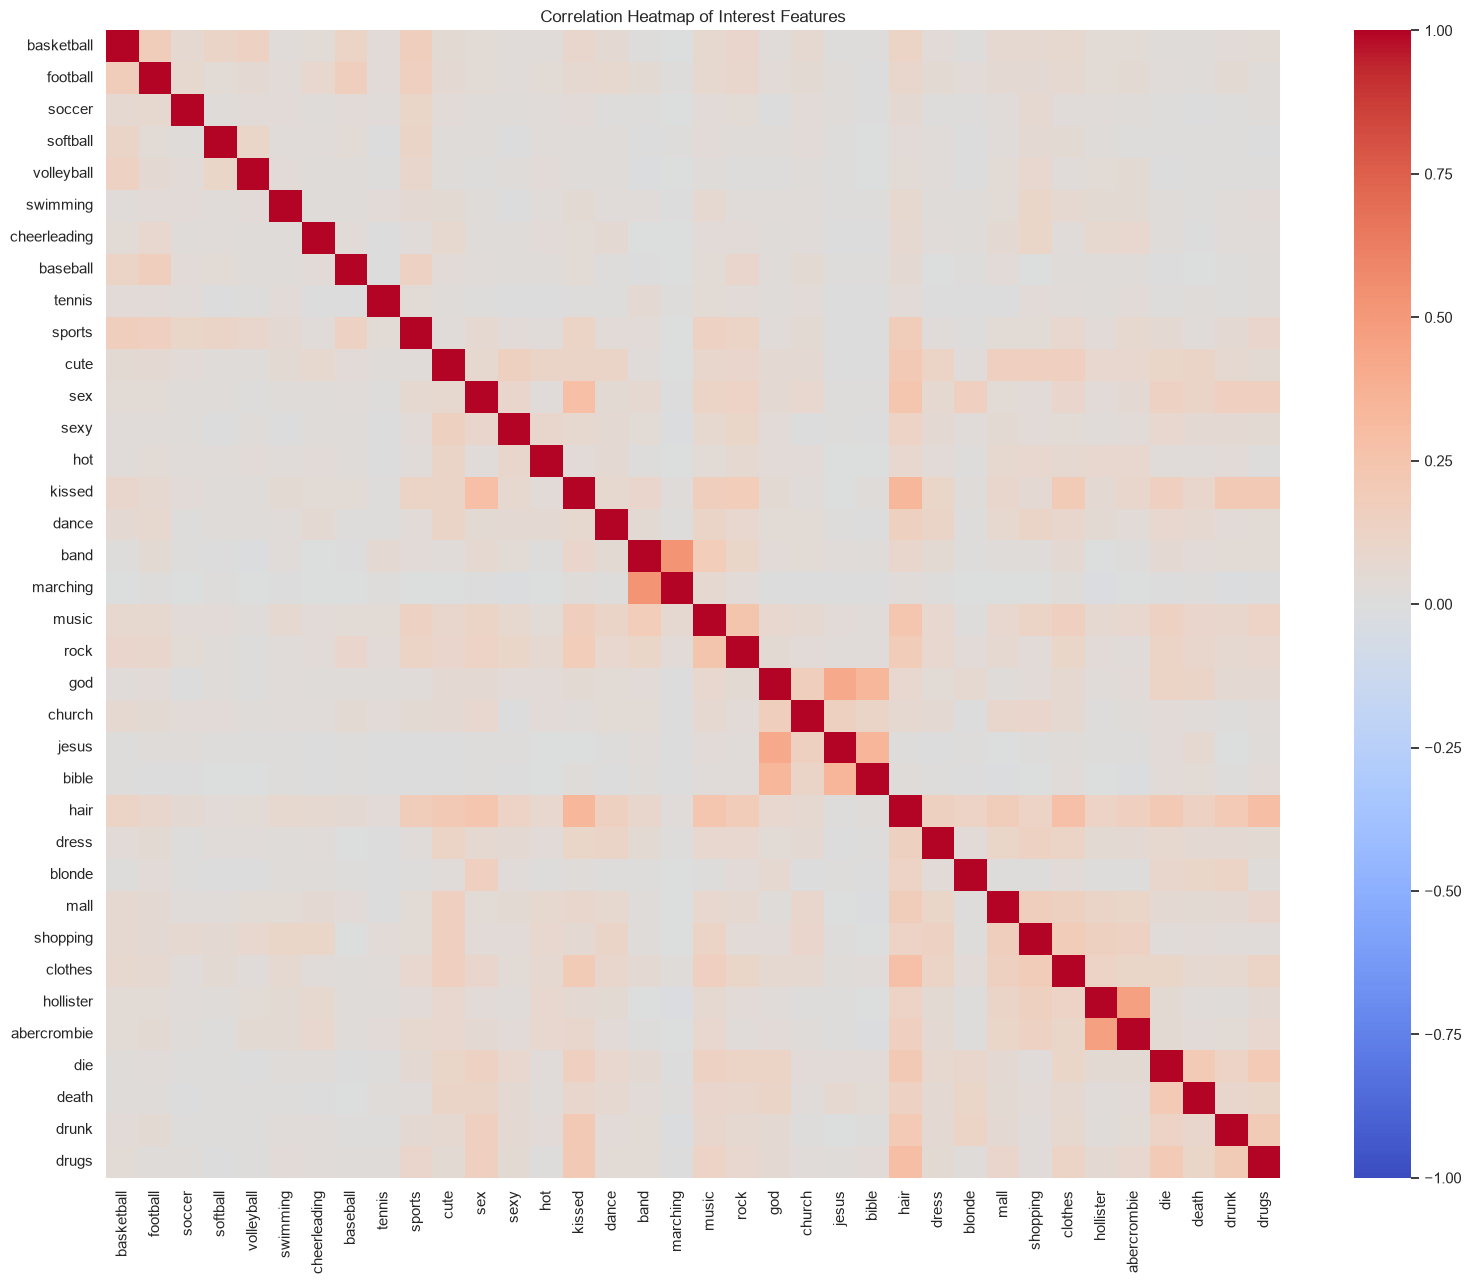

In [36]:
# Visualisasi correlation heatmap

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of Interest Features")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "interest_correlation_heatmap.png",
    dpi=150
)

plt.show()

In [37]:
# Menghindari penghitungan pasangan korelasi dua kali
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Mengubah matriks menjadi daftar pasangan fitur
correlation_pairs = (
    upper_triangle
    .stack()
)

# Memisahkan korelasi positif dan negatif
positive_correlations = (
    correlation_pairs[correlation_pairs > 0]
    .sort_values(ascending=False)
)

negative_correlations = (
    correlation_pairs[correlation_pairs < 0]
    .sort_values(ascending=True)
)

print("Top 15 Positive Correlations:")
display(
    positive_correlations.head(15).to_frame("Correlation")
)

print("\nTop 15 Negative Correlations:")
display(
    negative_correlations.head(15).to_frame("Correlation")
)

correlation_pairs.to_csv(
    TABLE_DIR / "correlation_pairs.csv"
)

Top 15 Positive Correlations:


,,Correlation
band,marching,0.528
hollister,abercrombie,0.464
god,jesus,0.420
jesus,bible,0.347
god,bible,0.337
kissed,hair,0.337
hair,drugs,0.294
sex,kissed,0.283
hair,clothes,0.275
music,rock,0.248



Top 15 Negative Correlations:


Correlation
marching   hollister         -0.018
bible      abercrombie       -0.010
           mall              -0.010
sexy       marching          -0.008
volleyball band              -0.008
marching   drunk             -0.008
band       hollister         -0.008
cute       marching          -0.007
soccer     marching          -0.007
sports     marching          -0.006
baseball   marching          -0.006
marching   mall              -0.006
softball   bible             -0.006
marching   abercrombie       -0.006
bible      hollister         -0.006

In [38]:
# Perbandingan korelasi: count-based vs binary (presence/absence)
X_binary = X_interest.gt(0).astype(int)

binary_correlation = X_binary.corr()

binary_upper = binary_correlation.where(
    np.triu(np.ones(binary_correlation.shape), k=1).astype(bool)
)

binary_pairs = binary_upper.stack().sort_values(ascending=False)

top_count_pairs = positive_correlations.head(15)

comparison = pd.DataFrame({
    "Count-Based": top_count_pairs,
    "Binary-Based": binary_pairs.loc[top_count_pairs.index]
})

display(comparison.round(3))

comparison.to_csv(TABLE_DIR / "correlation_count_vs_binary.csv")

,,Count-Based,Binary-Based
band,marching,0.528,0.382
hollister,abercrombie,0.464,0.473
god,jesus,0.420,0.167
jesus,bible,0.347,0.145
god,bible,0.337,0.106
kissed,hair,0.337,0.265
hair,drugs,0.294,0.191
sex,kissed,0.283,0.322
hair,clothes,0.275,0.224
music,rock,0.248,0.158


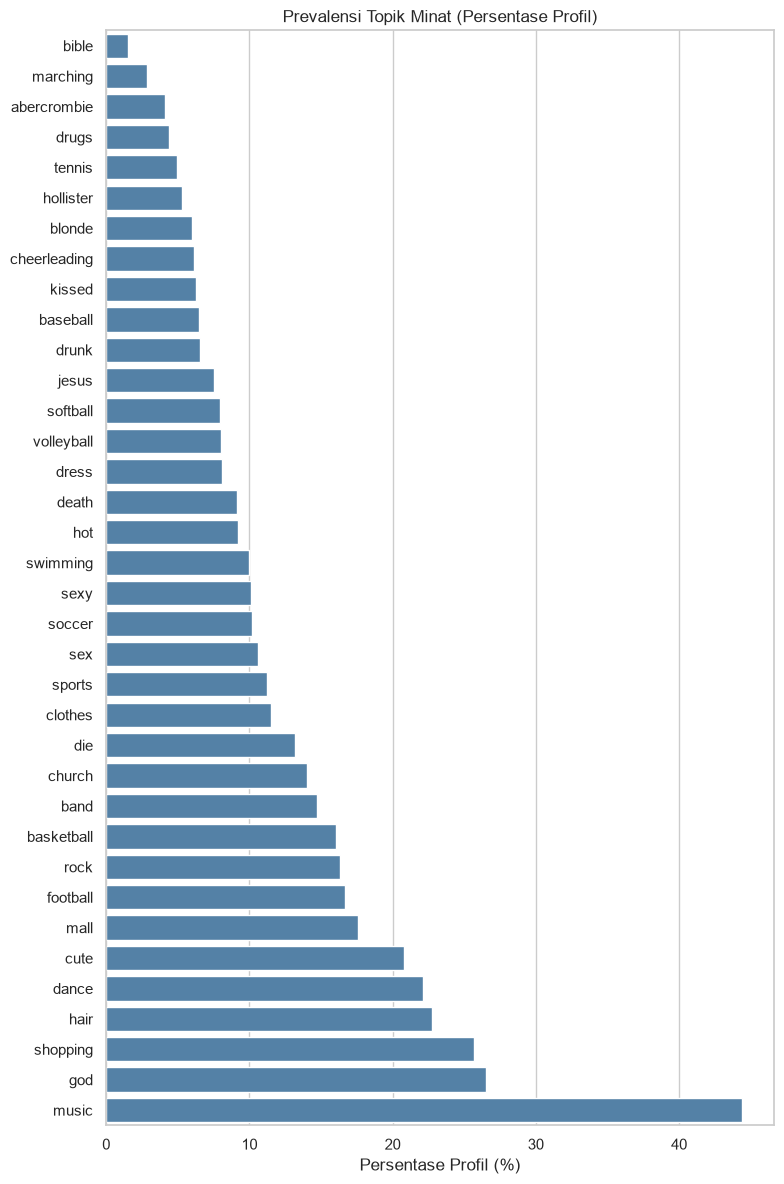

In [39]:
# Visualisasi 1: Prevalensi 36 topik minat
topic_plot_data = (
    topic_summary
    .reset_index()
    .rename(columns={"index": "Topic"})
    .sort_values("Profile Percentage", ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 12))

sns.barplot(
    data=topic_plot_data,
    x="Profile Percentage",
    y="Topic",
    color="steelblue",
    ax=ax
)

ax.set_title("Prevalensi Topik Minat (Persentase Profil)")
ax.set_xlabel("Persentase Profil (%)")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_topic_prevalence.png", dpi=150, bbox_inches="tight")
plt.show()

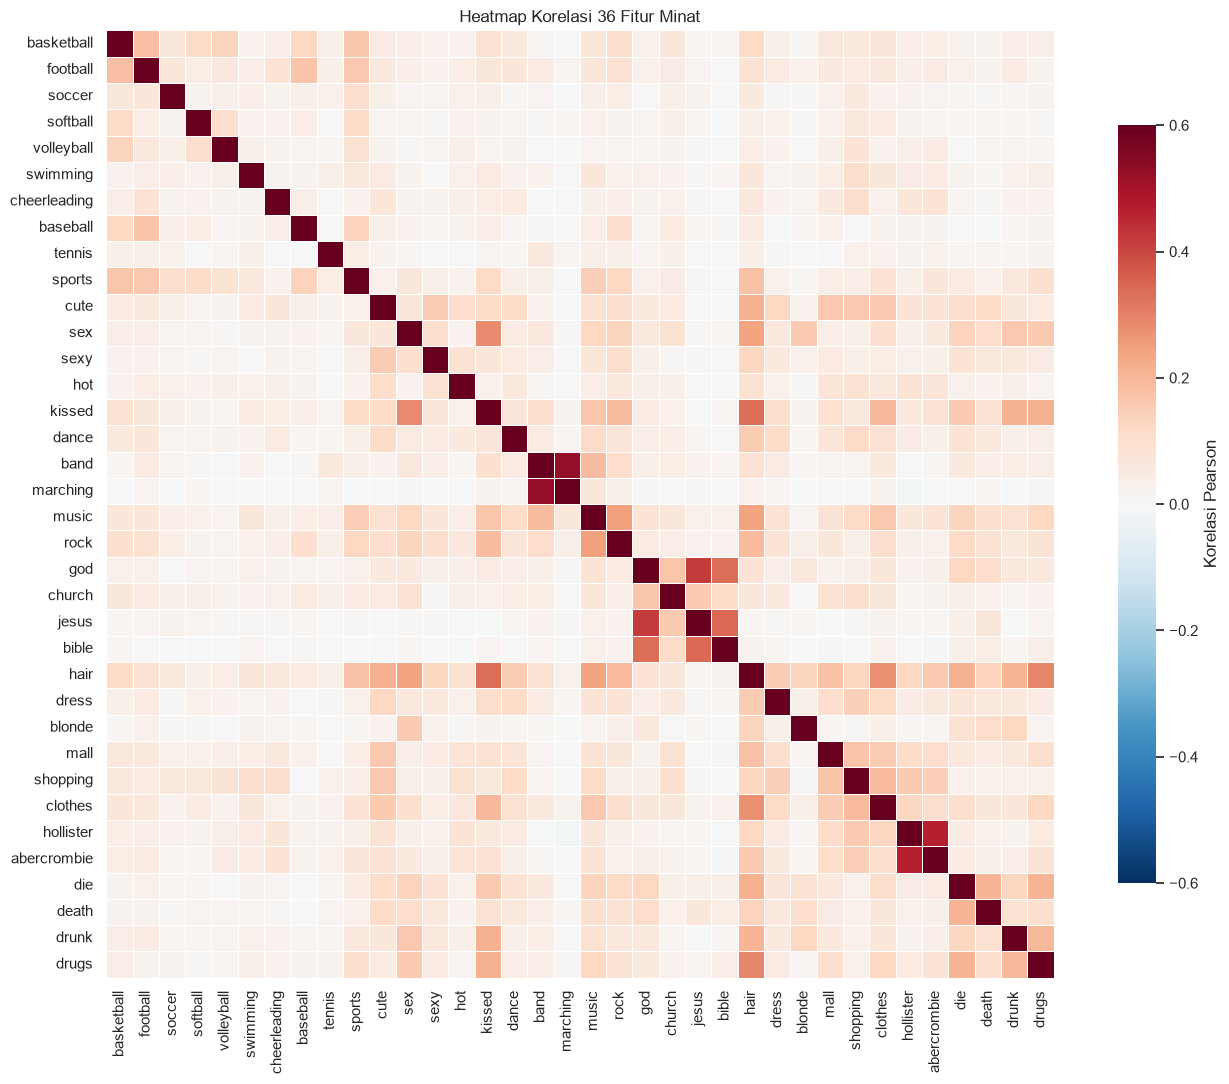

In [40]:
# Visualisasi 2: Heatmap korelasi antar fitur minat
fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    cmap="RdBu_r",
    center=0,
    vmin=-0.6,
    vmax=0.6,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Korelasi Pearson"},
    ax=ax
)

ax.set_title("Heatmap Korelasi 36 Fitur Minat")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

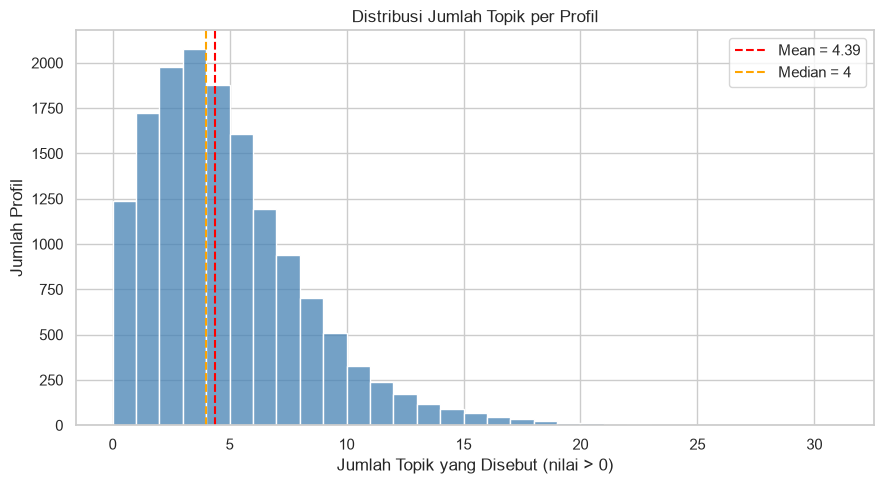

In [41]:
# Visualisasi 3: Distribusi jumlah topik per profil
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    topics_per_profile,
    binwidth=1,
    color="steelblue",
    ax=ax
)

ax.axvline(
    topics_per_profile.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {topics_per_profile.mean():.2f}"
)
ax.axvline(
    topics_per_profile.median(),
    color="orange",
    linestyle="--",
    label=f"Median = {topics_per_profile.median():.0f}"
)

ax.set_title("Distribusi Jumlah Topik per Profil")
ax.set_xlabel("Jumlah Topik yang Disebut (nilai > 0)")
ax.set_ylabel("Jumlah Profil")
ax.legend()

plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_topics_per_profile.png", dpi=150, bbox_inches="tight")
plt.show()

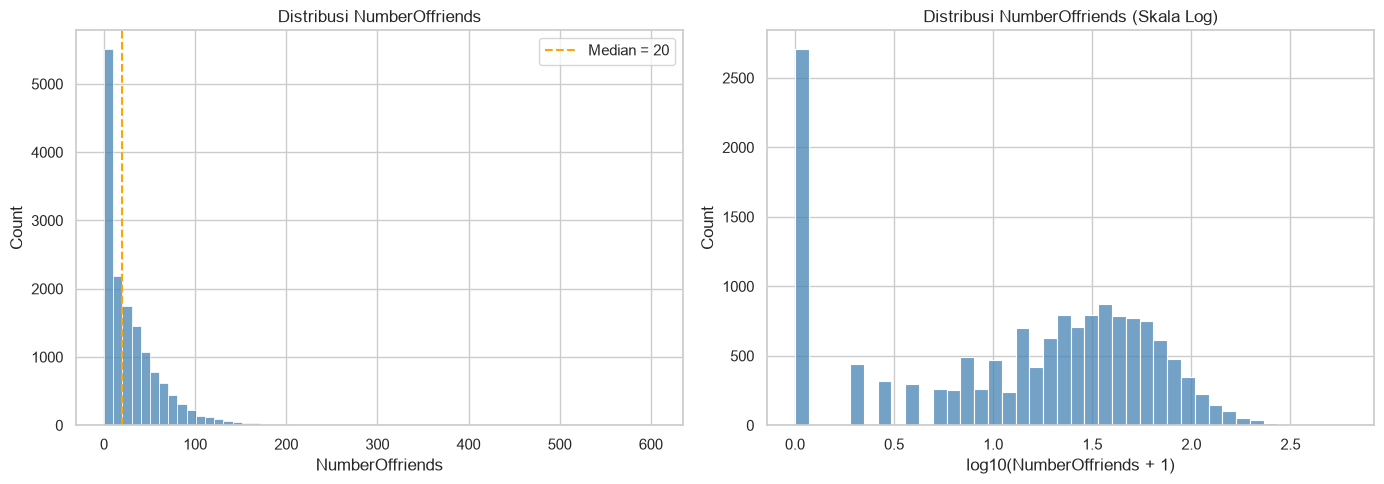

In [42]:
# Visualisasi 4: Distribusi NumberOffriends
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    friends_numeric,
    bins=60,
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Distribusi NumberOffriends")
axes[0].axvline(
    friends_numeric.median(),
    color="orange",
    linestyle="--",
    label=f"Median = {friends_numeric.median():.0f}"
)
axes[0].legend()

friends_log = np.log10(friends_numeric + 1)

sns.histplot(
    friends_log,
    bins=40,
    color="steelblue",
    ax=axes[1]
)
axes[1].set_title("Distribusi NumberOffriends (Skala Log)")
axes[1].set_xlabel("log10(NumberOffriends + 1)")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_friends_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Duplicate Interest Patterns

Mengidentifikasi profil yang memiliki pola nilai identik
pada seluruh fitur minat.

Pola minat yang sama tidak selalu berarti observasi
berasal dari siswa yang sama.

Oleh karena itu, hasil ini hanya digunakan sebagai
informasi tambahan dalam memahami karakteristik dataset.

In [43]:
duplicate_interest_count = X_interest.duplicated().sum()

duplicate_interest_percentage = (
    duplicate_interest_count / len(X_interest) * 100
)

print(
    "Duplicate Interest Patterns:",
    duplicate_interest_count
)

print(
    f"Percentage: {duplicate_interest_percentage:.2f}%"
)

# Melihat pola minat yang paling sering muncul
interest_pattern_frequency = (
    X_interest.value_counts()
    .head(10)
    .reset_index(name="Frequency")
)

display(interest_pattern_frequency)

Duplicate Interest Patterns: 4163
Percentage: 27.75%


,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,tennis,sports,cute,sex,sexy,hot,kissed,dance,band,marching,music,rock,god,church,jesus,bible,hair,dress,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs,Frequency
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1238
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,236
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,91
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,61
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,59
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,58
6,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,57
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,56
8,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,55
9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,54


## 10. EDA Findings and Conclusion

Bagian ini merangkum hasil utama dari Data Understanding
dan Exploratory Data Analysis.

Temuan EDA digunakan sebagai dasar pertimbangan dalam
menentukan strategi preprocessing dan feature engineering.

Perlu diingat bahwa temuan statistik tidak secara otomatis
menentukan tindakan pembersihan data. Setiap keputusan
perlu dipertimbangkan dan diuji pada tahap berikutnya.

In [44]:
findings = []

# 1. Missing values
missing_cols = df.isna().sum()
missing_cols = missing_cols[missing_cols > 0]

missing_evidence = (
    "; ".join(
        f"{col}: {count} ({count / len(df) * 100:.2f}%)"
        for col, count in missing_cols.items()
    )
    if len(missing_cols)
    else "No missing values found."
)

findings.append({
    "Finding": "Missing Values",
    "Evidence": missing_evidence,
    "Implication": (
        "Tentukan strategi penanganan missing values pada tahap preprocessing."
    )
})

# 2. Duplicate rows
findings.append({
    "Finding": "Full Duplicate Rows",
    "Evidence": (
        f"{duplicate_count} rows "
        f"({duplicate_percentage:.2f}%)."
    ),
    "Implication": (
        "Lakukan investigasi sebelum memutuskan apakah baris duplikat perlu dihapus."
    )
})

# 3. Age validation
findings.append({
    "Finding": "Age Data Quality",
    "Evidence": (
        f"{invalid_age} non-missing values cannot be converted to numeric."
    ),
    "Implication": (
        "Perlu investigasi terhadap format age sebelum digunakan dalam analisis lanjutan."
    )
})

# 4. Sparsity
findings.append({
    "Finding": "Interest Feature Sparsity",
    "Evidence": f"{sparsity:.2f}% of valid interest cells are zero.",
    "Implication": (
        "Pertimbangkan karakteristik sparse data dalam pemilihan representasi fitur."
    )
})

# 5. All-zero profiles
findings.append({
    "Finding": "All-Zero Interest Profiles",
    "Evidence": (
        f"{total_zero_profiles} profiles "
        f"({zero_profile_percentage:.2f}%)."
    ),
    "Implication": (
        "Evaluasi apakah profil tanpa informasi minat perlu dipertahankan "
        "atau dipisahkan dalam eksperimen."
    )
})

# 6. Duplicate interest patterns
findings.append({
    "Finding": "Duplicate Interest Patterns",
    "Evidence": (
        f"{duplicate_interest_count} rows "
        f"({duplicate_interest_percentage:.2f}%)."
    ),
    "Implication": (
        "Pola minat identik tidak otomatis merupakan duplikasi identitas siswa."
    )
})

# 7. Feature distribution
skewed_features = feature_distribution[
    feature_distribution["Skewness"].abs() > 2
]

findings.append({
    "Finding": "Skewed Interest Features",
    "Evidence": (
        f"{len(skewed_features)} features have absolute skewness greater than 2."
    ),
    "Implication": (
        "Pertimbangkan transformasi fitur sebagai salah satu eksperimen preprocessing."
    )
})

findings_df = pd.DataFrame(findings)

display(findings_df)

findings_df.to_csv(
    TABLE_DIR / "eda_findings.csv",
    index=False
)

,Finding,Evidence,Implication
0,Missing Values,gender: 1337 (8.91%); age: 2496 (16.64%),Tentukan strategi penanganan missing values pa...
1,Full Duplicate Rows,266 rows (1.77%).,Lakukan investigasi sebelum memutuskan apakah ...
2,Age Data Quality,276 non-missing values cannot be converted to ...,Perlu investigasi terhadap format age sebelum ...
3,Interest Feature Sparsity,87.80% of valid interest cells are zero.,Pertimbangkan karakteristik sparse data dalam ...
4,All-Zero Interest Profiles,1238 profiles (8.25%).,Evaluasi apakah profil tanpa informasi minat p...
5,Duplicate Interest Patterns,4163 rows (27.75%).,Pola minat identik tidak otomatis merupakan du...
6,Skewed Interest Features,36 features have absolute skewness greater tha...,Pertimbangkan transformasi fitur sebagai salah...


In [45]:
print("Dataset Overview")
print("----------------")

print("Total Profiles:", len(df))
print("Total Columns:", len(df.columns))
print("Profile Features:", len(profile_cols))
print("Interest Features:", len(interest_cols))

print("\nData Quality")
print("------------")

print("Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", duplicate_count)

print("\nInterest Characteristics")
print("------------------------")

print(f"Sparsity: {sparsity:.2f}%")
print("All-Zero Profiles:", total_zero_profiles)
print("Duplicate Interest Patterns:", duplicate_interest_count)

print("\nTop 5 Most Common Interests")
print("---------------------------")

display(
    topic_summary[
        ["Profile Count", "Profile Percentage"]
    ].head(5)
)

Dataset Overview
----------------
Total Profiles: 15000
Total Columns: 40
Profile Features: 4
Interest Features: 36

Data Quality
------------
Missing Values: 3833
Duplicate Rows: 266

Interest Characteristics
------------------------
Sparsity: 87.80%
All-Zero Profiles: 1238
Duplicate Interest Patterns: 4163

Top 5 Most Common Interests
---------------------------


,Profile Count,Profile Percentage
music,6661,44.407
god,3980,26.533
shopping,3856,25.707
hair,3407,22.713
dance,3323,22.153


# Exploratory Data Analysis (EDA)

## 1. Dataset Structure

Dataset terdiri dari **15.000 profil siswa** dengan total **40 kolom**, yang terbagi menjadi:

- **4 fitur profil:** `gradyear`, `gender`, `age`, dan `NumberOffriends`.
- **36 fitur minat:** berupa jumlah kemunculan kata kunci yang merepresentasikan minat siswa.

Secara semantik, 36 fitur minat dapat dikelompokkan menjadi enam kategori:

| Kategori | Jumlah Fitur |
|---|---:|
| Olahraga | 10 |
| Penampilan / Romantis | 8 |
| Musik | 5 |
| Belanja / Merek | 5 |
| Religi | 4 |
| Morbid / Berisiko | 4 |
| **Total** | **36** |

**Distribusi fitur profil:**

- `gradyear`: Tahun kelulusan 2006–2009 relatif seimbang, dengan proporsi sekitar 25% untuk setiap angkatan.
- `gender`: F sebesar 73,7%, M sebesar 17,4%, dan missing values sebesar 8,9%. Dari data gender yang tersedia, sekitar 80,9% merupakan perempuan.
- Seluruh 36 fitur minat memiliki tipe data integer non-negatif dan tidak mengandung missing values.

## 2. Data Quality Assessment

Missing values hanya ditemukan pada fitur profil, yaitu:

| Fitur | Missing Values | Persentase |
|---|---:|---:|
| `age` | 2.496 | 16,64% |
| `gender` | 1.337 | 8,91% |

Selain itu, ditemukan **266 full duplicate rows (1,77%)**. Baris-baris tersebut memiliki seluruh nilai kolom yang identik. Namun, karena dataset tidak menyediakan unique student ID, kesamaan seluruh nilai belum cukup untuk memastikan bahwa baris tersebut merupakan duplikasi identitas siswa.

Kolom `age` merupakan fitur dengan permasalahan kualitas data paling signifikan:

- Terdapat 276 nilai non-missing yang menggunakan format tanggal lokal Jerman, seperti `"16. Jun"`, `"17. Mrz"`, dan `"16. Dez"`, tanpa informasi tahun sehingga tidak dapat dipulihkan sebagai nilai usia.
- Setelah dikonversi menjadi numerik, terdapat 12.228 nilai usia.
- Dari nilai numerik tersebut, ditemukan 153 nilai yang berada di luar rentang usia wajar 13–25 tahun.
- Sebanyak 77 nilai usia berada di atas 100 tahun, dengan nilai maksimum 106,927.
- Dengan demikian, sebanyak 12.075 baris atau sekitar **80,5% dari seluruh profil** memiliki nilai usia numerik dalam rentang 13–25 tahun.

Sebaliknya, seluruh 36 fitur minat memiliki kualitas data yang sangat baik:

- 0 missing values.
- 0 nilai negatif.
- Seluruh nilai bertipe integer.

## 3. Interest Features Analysis

Seluruh fitur minat memiliki **median 0 dan mean di bawah 1**, yang menunjukkan bahwa sebagian besar siswa memiliki sedikit atau bahkan tidak memiliki kemunculan pada setiap kata kunci.

Berdasarkan frekuensi profil yang memiliki nilai positif (Gambar 1), lima topik paling populer adalah:

| Topik | Persentase Profil |
|---|---:|
| Music | 44,4% |
| God | 26,5% |
| Shopping | 25,7% |
| Hair | 22,7% |
| Dance | 22,2% |

Sementara itu, topik dengan frekuensi terendah adalah `bible` (1,5%) dan `marching` (2,9%).

**Interpretasi distribusi fitur minat:**

- Seluruh 36 fitur menunjukkan distribusi *highly right-skewed* dengan nilai skewness di atas 2.
- Fitur `blonde` memiliki skewness tertinggi, yaitu sekitar 117,251, akibat adanya nilai ekstrem sebesar 327.
- Distribusi jumlah topik per profil (Gambar 3) menunjukkan konsentrasi tertinggi di sekitar 3–4 topik, dengan ekor distribusi hingga 31 topik.

### 3.1. Percentile Analysis

Analisis percentile dilakukan untuk memahami distribusi nilai pada bagian atas setiap fitur minat serta mengidentifikasi potensi nilai ekstrem.

Hasil pemeriksaan percentile menunjukkan:

- Sebanyak 17 dari 36 fitur memiliki P99 ≤ 2 (47,2%).
- Sebanyak 19 dari 36 fitur memiliki P99 > 2 (52,8%).
- Nilai P99 berada dalam rentang 1–5.
- Nilai P99.5 mencapai maksimum 7 pada beberapa fitur.

Beberapa fitur menunjukkan perbedaan yang cukup besar antara nilai P99 dan nilai maksimum:

| Fitur | P99 | Maximum |
|---|---:|---:|
| `blonde` | 2 | 327 |
| `sex` | 4 | 114 |
| `god` | 5 | 52 |
| `swimming` | 3 | 31 |
| `dance` | 5 | 29 |

Temuan ini menunjukkan adanya ekor distribusi yang panjang (*heavy right tail*) dan nilai ekstrem pada beberapa fitur.

Oleh karena itu, transformasi `log1p` dipertimbangkan untuk mengurangi skewness dan pengaruh nilai ekstrem tanpa langsung menghilangkan informasi dari observasi tersebut.

## 4. Data Sparsity Analysis

Dataset memiliki tingkat sparsity yang cukup tinggi:

- **87,80%** dari seluruh sel fitur minat bernilai nol.
- Rata-rata setiap profil hanya memiliki sekitar **4,39 topik** yang tercatat.
- Sebanyak **1.238 profil (8,25%)** tidak memiliki minat yang tercatat sama sekali (*all-zero interest profiles*).
- Sebanyak **4.163 baris (27,75%)** merupakan pengulangan pola nilai pada 36 fitur minat yang telah muncul sebelumnya.

Profil all-zero tidak selalu berarti siswa tersebut benar-benar tidak memiliki minat. Hal ini hanya menunjukkan bahwa tidak terdapat nilai positif pada 36 kategori minat yang tersedia di dataset.

Temuan tambahan dari Gambar 4 menunjukkan bahwa distribusi `NumberOffriends` juga sangat *right-skewed*:

- Median jumlah teman adalah 20.
- Nilai maksimum mencapai 605.
- Sekitar 18% profil memiliki 0 teman.

Hal ini mengindikasikan adanya subpopulasi profil dengan informasi sosial yang sangat terbatas atau kemungkinan tingkat aktivitas yang rendah.

## 5. Feature Relationships Analysis

Berdasarkan matriks korelasi Pearson (Gambar 2), hubungan positif terkuat ditemukan pada pasangan fitur yang secara semantik memiliki keterkaitan:

| Pasangan Fitur | Korelasi Pearson |
|---|---:|
| band – marching | 0,53 |
| hollister – abercrombie | 0,46 |
| god – jesus | 0,42 |
| jesus – bible | 0,35 |
| kissed – hair | 0,34 |

Tidak ditemukan korelasi negatif yang bermakna. Nilai korelasi negatif yang ditemukan memiliki magnitudo sangat kecil, dengan nilai terendah sekitar -0,018.

**Perbandingan korelasi count vs. binary** menunjukkan beberapa pola menarik:

1. **Topik religi:** Korelasi `god–jesus` menurun dari 0,42 menjadi 0,17 pada representasi binary. Hal ini mengindikasikan bahwa hubungan pada data count sebagian dipengaruhi oleh intensitas penyebutan.
2. **Topik romantis:** Korelasi `sex–kissed` sedikit meningkat dari 0,28 menjadi 0,32 pada representasi binary.
3. **Topik musik dan merek:** Pasangan `band–marching` (0,53 menjadi 0,38) dan `hollister–abercrombie` (0,46 menjadi 0,47) menunjukkan hubungan yang relatif konsisten pada kedua representasi.

**Keterbatasan analisis korelasi:**

- Korelasi pada data count dapat mencampurkan hubungan antar-topik dengan faktor intensitas aktivitas profil.
- Pearson correlation pada data yang sangat sparse berpotensi memberikan gambaran hubungan yang kurang representatif terhadap pola asosiasi sebenarnya.
- Korelasi tidak menunjukkan hubungan sebab-akibat (*correlation does not imply causation*).

## 6. Preprocessing Recommendations

Berdasarkan hasil EDA dan evaluasi kualitas data, berikut rekomendasi preprocessing sebelum proses clustering:

| No. | Fitur / Proses | Rekomendasi |
|---|---|---|
| 1 | `age` | Nilai berformat tanggal Jerman dan usia di luar rentang 13–25 diubah menjadi `NaN`. Gunakan hanya untuk profiling cluster, bukan sebagai fitur clustering. |
| 2 | `gender` | Missing values diubah menjadi kategori `Unknown`. Gunakan hanya untuk profiling cluster. |
| 3 | Full Duplicate Rows | Lakukan investigasi sebelum penghapusan. Dokumentasikan jumlahnya dan pertimbangkan perbandingan hasil dengan dan tanpa full duplicates karena tidak tersedia unique student ID. |
| 4 | All-zero Profiles | Pisahkan 1.238 profil tanpa informasi minat sebagai segmen tersendiri (*no-interest-recorded segment*), kemudian lakukan clustering pada profil lainnya. Jumlah ini perlu dihitung ulang setelah kebijakan duplicate ditentukan. |
| 5 | Feature Representation | Uji dua representasi fitur: `log1p + standardization` untuk mempertahankan informasi intensitas dan binary presence/absence untuk mengisolasi pola keberadaan topik. |
| 6 | Extreme Values | Gunakan transformasi `log1p` untuk mengurangi skewness dan pengaruh nilai ekstrem. Winsorization tidak diterapkan secara otomatis. Dampak clipping berbasis percentile dapat dievaluasi sebagai eksperimen alternatif apabila diperlukan. |
| 7 | Feature Selection | Gunakan hanya 36 fitur minat sebagai input clustering. Fitur profil digunakan untuk interpretasi dan karakterisasi cluster. |
| 8 | Outlier Removal | Tidak dilakukan penghapusan outlier berbasis IQR secara otomatis. Sebanyak 33 fitur memiliki IQR = 0, sedangkan 3 fitur (`music`, `god`, dan `shopping`) memiliki IQR = 1. Pendekatan IQR berpotensi mengidentifikasi nilai positif sebagai outlier, padahal nilai tersebut dapat mengandung informasi penting. |

## 7. EDA Conclusion

Berdasarkan hasil Exploratory Data Analysis, dataset memiliki kualitas fitur minat yang baik, tetapi menunjukkan karakteristik sparsity tinggi, distribusi yang sangat tidak seimbang, serta beberapa permasalahan kualitas data pada fitur profil.

Beberapa temuan utama adalah:

- Terdapat 36 fitur minat tanpa missing values, nilai negatif, maupun nilai non-integer.
- Sebanyak 87,80% sel fitur minat bernilai nol.
- Seluruh fitur menunjukkan distribusi right-skewed, sehingga transformasi data perlu dipertimbangkan.
- Terdapat 1.238 profil tanpa informasi minat yang tercatat.
- Beberapa pasangan fitur menunjukkan korelasi positif yang selaras dengan keterkaitan topiknya.
- Analisis P99 dan IQR menunjukkan adanya nilai ekstrem serta distribusi yang sangat sparse.

Berdasarkan temuan tersebut, proses clustering difokuskan pada **36 fitur minat**, dengan membandingkan dua pendekatan representasi fitur, yaitu:

1. **Count-based representation:** menggunakan transformasi `log1p` dan standardisasi untuk mempertahankan informasi intensitas kemunculan setiap topik.
2. **Binary-based representation:** menggunakan nilai presence/absence untuk mengidentifikasi pola keberadaan minat tanpa mempertimbangkan intensitas kemunculannya.

Sementara itu, fitur profil seperti `gradyear`, `gender`, `age`, dan `NumberOffriends` digunakan untuk membantu interpretasi dan karakterisasi setiap cluster, bukan sebagai input utama clustering.

Hasil EDA ini menjadi dasar dalam menentukan strategi preprocessing dan eksperimen model clustering pada tahap selanjutnya.